# 🚀 Practice Day 62

**📅 Date:** 2026-11-06  
📁 Category: Phase 2 · SQL 중급(JOIN·서브쿼리·CASE WHEN) (Round 5/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice JOIN, a subquery, and CASE WHEN in DuckDB SQL — the same yoga studio data as yesterday, solved a different way
  (DuckDB SQL의 JOIN·서브쿼리·CASE WHEN 연습 — 어제와 같은 요가 스튜디오 데이터를 다른 방식으로 풀어보기)
- Find each instructor's total booking count, which bookings cost more than average, and how fees split into tiers
  (강사별 총 예약건수, 평균보다 비싼 예약, 요금이 구간별로 어떻게 나뉘는지 파악하기)

---
# 📂 Dataset

**Dataset Name:** Lotus & Line Yoga Studio — same 3 tables as Day 61, solved with SQL this time / Lotus & Line 요가 스튜디오 — 강사·클래스·예약 (Day 61과 동일 데이터, SQL로 재풀이)

**Source:** Synthetically generated for practice, same generation code as Day 61 / 실습을 위해 코드로 생성, Day 61과 동일한 생성 코드

**Description:** The same `instructors` (8), `classes` (15), and `bookings` (320) tables from yesterday's file. This time, instead of pandas merge, the focus is on answering similar questions using DuckDB SQL — JOIN across all three tables, a subquery, and CASE WHEN. Fees are in USD.
(어제(Day 61) 만든 것과 동일한 instructors(8)·classes(15)·bookings(320) 3테이블입니다. 이번에는 pandas merge 대신 duckdb.sql()의 JOIN(3테이블 전체 연결), 서브쿼리, CASE WHEN을 사용해 비슷한 질문에 답하는 데 초점을 둡니다. 요금은 USD입니다.)

## Dataset Preview

In [1]:
# Dataset Preview
import pandas as pd
import numpy as np
from IPython.display import display

np.random.seed(42)
rng = np.random.default_rng(42)

# --- instructors ---
instructors_data = [
    ('Maya Lindqvist', 'Vinyasa'),
    ('Devon Okafor', 'Vinyasa'),
    ('Priya Raman', 'Hatha'),
    ('Sofia Marchetti', 'Pilates'),
    ('Kai Tanaka', 'Pilates'),
    ('Elena Vasquez', 'Restorative'),
    ('Marcus Reilly', 'Power Yoga'),
    ('Naomi Chen', 'Restorative'),
]
instructors = pd.DataFrame(instructors_data, columns=['instructor_name', 'specialty'])
instructors.insert(0, 'instructor_id', [f'I{str(i).zfill(2)}' for i in range(1, len(instructors) + 1)])

# --- classes ---
class_names_by_specialty = {
    'Vinyasa': ['Sunrise Flow', 'Power Flow'],
    'Hatha': ['Gentle Hatha', 'Morning Hatha'],
    'Pilates': ['Mat Pilates', 'Reformer Basics'],
    'Restorative': ['Deep Rest', 'Yin & Restore'],
    'Power Yoga': ['Power Hour'],
}
instr_by_spec = {}
for _, row in instructors.iterrows():
    instr_by_spec.setdefault(row['specialty'], []).append(row['instructor_id'])

class_rows = []
cid = 1
for spec, names in class_names_by_specialty.items():
    for name in names:
        for instr_id in instr_by_spec[spec]:
            class_rows.append({'class_id': f'C{str(cid).zfill(3)}', 'class_name': name,
                                'instructor_id': instr_id, 'class_type': spec})
            cid += 1
classes = pd.DataFrame(class_rows)
avg_price = {'Vinyasa': 28, 'Hatha': 22, 'Pilates': 32, 'Restorative': 20, 'Power Yoga': 30}  # USD per class

# --- bookings (some classes booked far more often than others) ---
n_bookings = 320
class_weight = rng.gamma(shape=2.0, scale=1.0, size=len(classes))
class_p = class_weight / class_weight.sum()
booking_class = rng.choice(classes['class_id'].values, size=n_bookings, replace=True, p=class_p)
booking_dates = pd.to_datetime('2024-01-01') + pd.to_timedelta(rng.integers(0, 200, size=n_bookings), unit='D')

class_type_map = dict(zip(classes['class_id'], classes['class_type']))
rows = []
for i in range(n_bookings):
    cid_ = booking_class[i]
    ct = class_type_map[cid_]
    noise = rng.normal(1.0, 0.06)
    fee = int(round(avg_price[ct] * noise))  # nearest USD
    rows.append({'booking_id': f'B{str(i+1).zfill(4)}', 'class_id': cid_, 'booking_date': booking_dates[i], 'fee': fee})
bookings = pd.DataFrame(rows).sort_values('booking_date').reset_index(drop=True)

print("Instructors:")
display(instructors)
print("\nClasses:")
display(classes.head())
print("\nBookings:")
display(bookings.head())


Instructors:


,instructor_id,instructor_name,specialty
0,I01,Maya Lindqvist,Vinyasa
1,I02,Devon Okafor,Vinyasa
2,I03,Priya Raman,Hatha
3,I04,Sofia Marchetti,Pilates
4,I05,Kai Tanaka,Pilates
5,I06,Elena Vasquez,Restorative
6,I07,Marcus Reilly,Power Yoga
7,I08,Naomi Chen,Restorative



Classes:


,class_id,class_name,instructor_id,class_type
0,C001,Sunrise Flow,I01,Vinyasa
1,C002,Sunrise Flow,I02,Vinyasa
2,C003,Power Flow,I01,Vinyasa
3,C004,Power Flow,I02,Vinyasa
4,C005,Gentle Hatha,I03,Hatha



Bookings:


,booking_id,class_id,booking_date,fee
0,B0065,C002,2024-01-01,26
1,B0193,C001,2024-01-01,27
2,B0137,C005,2024-01-02,19
3,B0138,C008,2024-01-02,35
4,B0082,C013,2024-01-03,20


## Dataset Information

In [2]:
# Dataset Information
print("Instructors:", instructors.shape)
instructors.info()
print("\nClasses:", classes.shape)
classes.info()
print("\nBookings:", bookings.shape)
bookings.info()

print("\n--- Describe: Instructors ---")
display(instructors.describe(include='all'))
print("\n--- Describe: Classes ---")
display(classes.describe(include='all'))
print("\n--- Describe: Bookings ---")
display(bookings.describe(include='all'))


Instructors: (8, 3)
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   instructor_id    8 non-null      str  
 1   instructor_name  8 non-null      str  
 2   specialty        8 non-null      str  
dtypes: str(3)
memory usage: 324.0 bytes

Classes: (15, 4)
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   class_id       15 non-null     str  
 1   class_name     15 non-null     str  
 2   instructor_id  15 non-null     str  
 3   class_type     15 non-null     str  
dtypes: str(4)
memory usage: 612.0 bytes

Bookings: (320, 4)
<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   booking_id

,instructor_id,instructor_name,specialty
count,8,8,8
unique,8,8,5
top,I01,Maya Lindqvist,Vinyasa
freq,1,1,2



--- Describe: Classes ---


,class_id,class_name,instructor_id,class_type
count,15,15,15,15
unique,15,9,8,5
top,C001,Sunrise Flow,I01,Vinyasa
freq,1,2,2,4



--- Describe: Bookings ---


,booking_id,class_id,booking_date,fee
count,320,320,320,320.000000
unique,320,15,NaN,NaN
top,B0065,C002,NaN,NaN
freq,1,39,NaN,NaN
mean,NaN,NaN,2024-04-09 13:39:00,25.940625
min,NaN,NaN,2024-01-01 00:00:00,16.000000
25%,NaN,NaN,2024-02-18 18:00:00,21.000000
50%,NaN,NaN,2024-04-13 00:00:00,26.000000
75%,NaN,NaN,2024-05-29 00:00:00,30.000000
max,NaN,NaN,2024-07-18 00:00:00,35.000000


---
# ❓ Business Questions

1. **(Analysis — JOIN)** Joining all three tables, what is each instructor's total booking count?
   (3개 테이블을 JOIN했을 때, 강사별 총 예약건수는?)
2. **(Analysis — Subquery)** Using a subquery to find the average booking fee, which bookings cost more than that average?
   (서브쿼리로 평균 예약 요금을 구했을 때, 그 평균보다 비싼 예약은?)
3. **(Analysis — CASE WHEN)** Using CASE WHEN to bucket each booking's fee into Low (<$22)/Medium ($22-$29)/High (>$29) tiers, how many bookings fall into each tier?
   (CASE WHEN으로 예약 요금을 저($22 미만)/중($22~$29)/고($29 초과) 구간으로 나누면, 구간별 건수는?)
4. **(Visualization)** Compare total booking counts across all instructors.
   (강사별 총 예약건수를 비교하면?)
5. **(Visualization)** Compare booking counts across the three fee tiers.
   (3개 요금 구간별 예약건수를 비교하면?)

---
# 🔍 Data Cleaning Check


In [3]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("===== instructors =====")
print("Missing values")
print(instructors.isnull().sum())
print("\nDuplicate rows:", instructors.duplicated().sum())
print("\nDtypes")
print(instructors.dtypes)
print("\nColumn names")
print(instructors.columns.tolist())
obj_cols = instructors.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(instructors[obj_cols].nunique())
print()

print("===== classes =====")
print("Missing values")
print(classes.isnull().sum())
print("\nDuplicate rows:", classes.duplicated().sum())
print("\nDtypes")
print(classes.dtypes)
print("\nColumn names")
print(classes.columns.tolist())
obj_cols = classes.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(classes[obj_cols].nunique())
print()

print("===== bookings =====")
print("Missing values")
print(bookings.isnull().sum())
print("\nDuplicate rows:", bookings.duplicated().sum())
print("\nDtypes")
print(bookings.dtypes)
print("\nColumn names")
print(bookings.columns.tolist())
obj_cols = bookings.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(bookings[obj_cols].nunique())
print()


===== instructors =====
Missing values
instructor_id      0
instructor_name    0
specialty          0
dtype: int64

Duplicate rows: 0

Dtypes
instructor_id      str
instructor_name    str
specialty          str
dtype: object

Column names
['instructor_id', 'instructor_name', 'specialty']

Text columns — unique counts
instructor_id      8
instructor_name    8
specialty          5
dtype: int64

===== classes =====
Missing values
class_id         0
class_name       0
instructor_id    0
class_type       0
dtype: int64

Duplicate rows: 0

Dtypes
class_id         str
class_name       str
instructor_id    str
class_type       str
dtype: object

Column names
['class_id', 'class_name', 'instructor_id', 'class_type']

Text columns — unique counts
class_id         15
class_name        9
instructor_id     8
class_type        5
dtype: int64

===== bookings =====
Missing values
booking_id      0
class_id        0
booking_date    0
fee             0
dtype: int64

Duplicate rows: 0

Dtypes
booking_id 

---
# 📊 Analysis

## Question 1

**Question:** Joining all three tables, what is each instructor's total booking count? (3개 테이블 JOIN 시, 강사별 총 예약건수는?)

**Result:**  
Elena Vasquez has the most bookings with **58**, and Marcus Reilly the fewest with **4**.  
(Elena Vasquez가 **58**건으로 예약이 가장 많고, Marcus Reilly가 **4**건으로 가장 적습니다.)  

**Insight:**  
The eight instructors add up to **320** bookings, and Elena Vasquez has **54** more than Marcus Reilly.  
(강사 8명의 예약을 더하면 **320**건이고, Elena Vasquez는 Marcus Reilly보다 **54**건 많습니다.)

In [4]:
# Question 1 (DuckDB, JOIN): total booking count per instructor
import duckdb

booking_count_by_instructor = duckdb.sql("""
    SELECT
        i.instructor_id,
        i.instructor_name,
        COUNT(b.booking_id) AS booking_count
    FROM instructors i
    JOIN classes c ON i.instructor_id = c.instructor_id
    JOIN bookings b ON c.class_id = b.class_id
    GROUP BY i.instructor_id, i.instructor_name
    ORDER BY booking_count DESC
""").df()

booking_count_by_instructor

,instructor_id,instructor_name,booking_count
0,I06,Elena Vasquez,58
1,I04,Sofia Marchetti,53
2,I02,Devon Okafor,52
3,I03,Priya Raman,43
4,I05,Kai Tanaka,39
5,I01,Maya Lindqvist,37
6,I08,Naomi Chen,34
7,I07,Marcus Reilly,4


## Question 2

**Question:** Using a subquery to find the average booking fee, which bookings cost more than that average? (평균 요금보다 비싼 예약은?)

**Result:**  
The average fee is **$25.94**, and **178** bookings cost more than that, starting at **$26** and going up to **$35**.  
(평균 요금은 **$25.94**이고, 그보다 비싼 예약은 **178**건이며 **$26**부터 **$35**까지입니다.)  

**Insight:**  
Above-average bookings are **178** of **320**, so every fee from **$26** up is above the average.  
(평균보다 비싼 예약은 **320**건 중 **178**건이며, **$26** 이상의 요금은 모두 평균보다 높습니다.)

In [5]:
# Question 2 (DuckDB, subquery): bookings with a fee above the average fee
avg_fee = duckdb.sql("SELECT ROUND(AVG(fee), 2) AS avg_fee FROM bookings").df()
print(avg_fee)

above_avg_bookings = duckdb.sql("""
    SELECT
        booking_id,
        fee
    FROM bookings
    WHERE fee > (SELECT AVG(fee) FROM bookings)
    ORDER BY fee
""").df()

print("Bookings above average:", len(above_avg_bookings))
above_avg_bookings


   avg_fee
0    25.94
Bookings above average: 178


,booking_id,fee
0,B0205,26
1,B0206,26
2,B0089,26
3,B0055,26
4,B0170,26
...,...,...
173,B0032,35
174,B0195,35
175,B0290,35
176,B0278,35


## Question 3

**Question:** Using CASE WHEN to bucket each booking's fee into tiers, how many bookings fall into each tier? (CASE WHEN으로 요금 구간을 나누면 구간별 건수는?)

**Result:**  
Medium has the most bookings with **128**, followed by High with **98** and Low with **94**.  
(Medium이 **128**건으로 가장 많고, High **98**건, Low **94**건이 뒤를 잇습니다.)  

**Insight:**  
The three tiers add up to **320** bookings, and Medium is **30** more than High.  
(세 구간을 더하면 **320**건이고, Medium은 High보다 **30**건 많습니다.)

In [6]:
# Question 3 (DuckDB, CASE WHEN): bucket bookings by fee tier
tier_counts = duckdb.sql("""
    SELECT
        CASE
            WHEN fee < 22 THEN 'Low'
            WHEN fee BETWEEN 22 AND 29 THEN 'Medium'
            ELSE 'High'
        END AS fee_tier,
        COUNT(*) AS tier_count
    FROM bookings
    GROUP BY fee_tier
    ORDER BY MIN(fee)
""").df()

tier_counts

,fee_tier,tier_count
0,Low,94
1,Medium,128
2,High,98


---
# 📈 Visualization

**Chart 1:** Bar chart — total booking count by instructor (막대그래프: 강사별 총 예약건수)

*Interpretation:*  
Elena Vasquez has the longest bar at **58**, followed by Sofia Marchetti at **53** and Devon Okafor at **52**. Marcus Reilly has the shortest at **4**.  
(Elena Vasquez 막대가 **58**건으로 가장 길고, Sofia Marchetti **53**건, Devon Okafor **52**건이 뒤를 잇습니다. Marcus Reilly가 **4**건으로 가장 짧습니다.)  

---

**Chart 2:** Bar chart — booking count by fee tier (막대그래프: 요금 구간별 예약건수)

*Interpretation:*  
Medium has the tallest bar at **128**, while Low is **94** and High is **98**.  
(Medium 막대가 **128**건으로 가장 높고, Low는 **94**건, High는 **98**건입니다.)


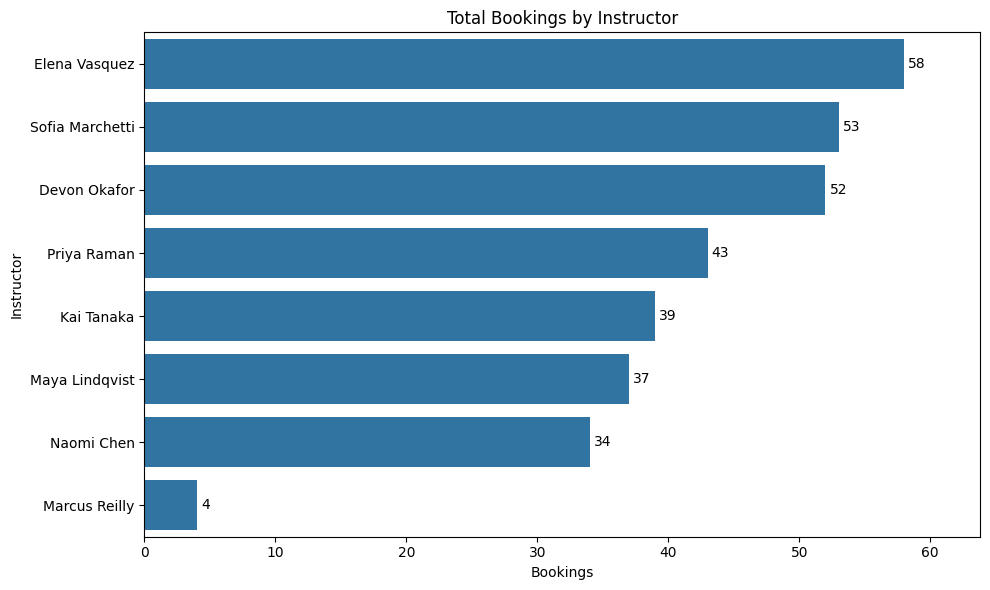

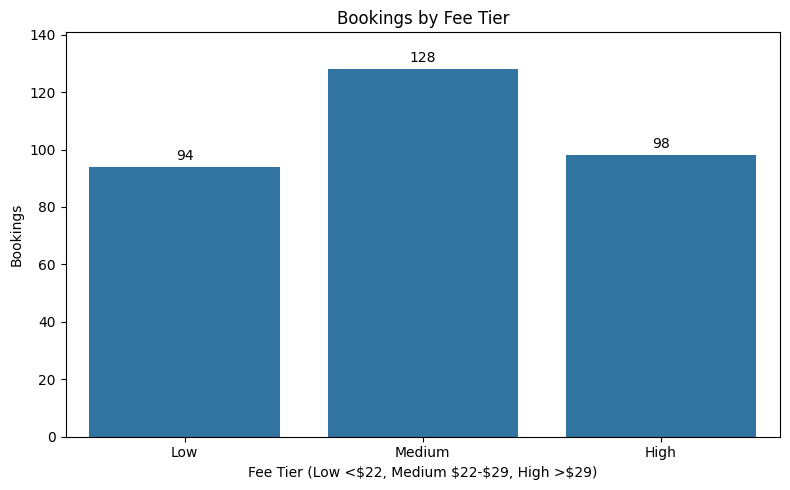

In [7]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: booking count by instructor (bar), same order as the Q1 table
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='booking_count', y='instructor_name', data=booking_count_by_instructor, ax=ax, errorbar=None)
ax.set_title('Total Bookings by Instructor')
ax.set_xlabel('Bookings')
ax.set_ylabel('Instructor')
ax.bar_label(ax.containers[0], padding=3)
ax.margins(x=0.1)
plt.tight_layout()
plt.show()

# Chart 2: booking count by fee tier (bar), tiers in order from Low to High
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x='fee_tier', y='tier_count', data=tier_counts, ax=ax, errorbar=None)
ax.set_title('Bookings by Fee Tier')
ax.set_xlabel(r'Fee Tier (Low <\$22, Medium \$22-\$29, High >\$29)')
ax.set_ylabel('Bookings')
ax.bar_label(ax.containers[0], padding=3)
ax.margins(y=0.1)
plt.tight_layout()
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Elena Vasquez has the most bookings (**58**), and Marcus Reilly has only **4**.  
  (Elena Vasquez의 예약이 가장 많고(**58**건), Marcus Reilly는 **4**건뿐입니다.)  
- **178** of **320** bookings cost more than the **$25.94** average fee.  
  (**320**건 중 **178**건이 평균 요금 **$25.94**보다 비쌉니다.)  
- Medium fees are the biggest tier at **128** bookings.  
  (Medium 요금 구간이 **128**건으로 가장 큽니다.)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Look into why Marcus Reilly has only **4** bookings against **58** for the top instructor.  
   (최고 강사의 **58**건에 비해 Marcus Reilly가 **4**건뿐인 이유를 살펴봅니다.)  
2. Treat the **$26–$35** bookings, which are **178** of **320**, as the above-average group when you study fees.  
   (요금을 분석할 때 **320**건 중 **178**건인 **$26–$35** 예약을 평균 이상 그룹으로 봅니다.)  
3. Plan most class capacity for the Medium tier, which has **128** bookings.  
   (**128**건인 Medium 구간에 맞춰 클래스 정원을 가장 많이 계획합니다.)  


---
# ❌ Mistakes
*What mistakes did I make today?*

- In the Question 1 join I left out a comma after `i.instructor_name` and used `c.booking_id`, but `classes` has no `booking_id` column.  
  (Question 1 JOIN에서 `i.instructor_name` 뒤에 쉼표를 빼먹었고, `classes`에는 없는 `c.booking_id`를 썼습니다.)  
- In Question 2 I used `HAVING` without a `GROUP BY`.  
  (Question 2에서 `GROUP BY` 없이 `HAVING`을 썼습니다.)  


---
# ✅ What I Learned
*Today's biggest lesson*

- Join `classes` and `bookings` on the shared `class_id`, not on a column that only one table has.  
  (`classes`와 `bookings`는 한 테이블에만 있는 열이 아니라 공통 열 `class_id`로 JOIN합니다.)  
- Use `WHERE` to filter rows against a subquery average, and `HAVING` only after a `GROUP BY`.  
  (서브쿼리 평균과 비교해 행을 거를 때는 `WHERE`를 쓰고, `HAVING`은 `GROUP BY` 뒤에만 씁니다.)  

---
# 🧠 Reflection

**What was difficult?**  
Writing the three-table JOIN and the subquery filter.  
(3개 테이블 JOIN과 서브쿼리 필터를 쓰는 것)

**Why?**  
I joined on a column the table does not have and used `HAVING` where `WHERE` belongs.  
(테이블에 없는 열로 JOIN했고, `WHERE`를 써야 할 곳에 `HAVING`을 썼음)

**How did I solve it?**  
Joined on `class_id` and moved the subquery comparison to `WHERE`.  
(`class_id`로 JOIN하고 서브쿼리 비교를 `WHERE`로 옮김)

**What would I do differently next time?**  
List each table's columns before writing the `ON` conditions.  
(`ON` 조건을 쓰기 전에 각 테이블의 열을 먼저 확인하기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
I can join three tables and filter against a subquery after fixing my mistakes.  
(실수를 고친 뒤에는 3개 테이블을 JOIN하고 서브쿼리로 거를 수 있습니다.)  

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Day 63: Visualization storytelling  
  (Day 63: 시각화 스토리텔링)  
